# Method check: does attention find a known signal?

The shortest possible test of the method. Sequence class is decided by a four
base motif at a fixed position. Everything else is random, and 10% of labels
are flipped as noise.

A working model has to put its attention on that motif. The data is synthetic
so the right answer is known. **No biological claim is made here.**

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
import crispr_attention as ca

np.random.seed(0)
torch.manual_seed(0)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

device: cpu


## 1. Data

Each group stands for one amplicon. Sequences within a group share a backbone and the same signal window, and differ by random noise elsewhere. This reproduces the structure of amplicon sequencing data, where many near identical reads come from one site.

In [2]:
X, y, groups, window = ca.make_synthetic(
    n_groups=500, per_group=20, length=60,
    signal_start=28, signal_width=4, label_noise=0.10, seed=0)

print("sequences      :", X.shape)
print("groups         :", len(np.unique(groups)))
print("signal window  :", window)
print("class balance  :", np.bincount(y) / len(y))
print("\nfirst sequence :", ca.decode(X[0]))

sequences      : (10000, 60)
groups         : 500
signal window  : (28, 32)
class balance  : [0.6264 0.3736]

first sequence : TGGCCAAAATGTGGTGGGGTCTGACTGATGGCATAGACCCCAAAAGGGCGTCCTTTCGTG


## 2. Group aware split

Splitting rows at random would place near copies of the same sequence in both training and test data, which inflates every metric. Splitting by group prevents that.

In [3]:
tr, va, te = ca.group_split(groups, train=0.7, val=0.15, seed=0)
print(f"train {len(tr):5d} rows, {len(np.unique(groups[tr])):3d} groups")
print(f"val   {len(va):5d} rows, {len(np.unique(groups[va])):3d} groups")
print(f"test  {len(te):5d} rows, {len(np.unique(groups[te])):3d} groups")
print("\ntrain and test share no group:", set(groups[tr]).isdisjoint(set(groups[te])))

train  7000 rows, 350 groups
val    1500 rows,  75 groups
test   1500 rows,  75 groups

train and test share no group: True


## 3. Model

The vocabulary holds six tokens, so the embedding stays small. Padding has index 0 and is removed from the attention softmax, so padded positions cannot receive weight.

In [4]:
model = ca.AttentionBiLSTM(num_classes=2, embed_dim=32, hidden_dim=64, dropout=0.3)
print(model)
print(f"\ntrainable parameters: {model.n_parameters():,}")

AttentionBiLSTM(
  (embedding): Embedding(6, 32, padding_idx=0)
  (pos): PositionalEncoding()
  (lstm): LSTM(32, 64, batch_first=True, bidirectional=True)
  (attn): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)

trainable parameters: 58,947


In [5]:
model, history = ca.fit(model, X[tr], y[tr], X[va], y[va],
                        epochs=30, batch_size=128, lr=1e-3, patience=5, seed=0)

epoch   1  train loss 0.6694  val macro F1 0.7910


epoch   2  train loss 0.4654  val macro F1 0.8653


epoch   3  train loss 0.3955  val macro F1 0.8532


epoch   4  train loss 0.3714  val macro F1 0.8805


epoch   5  train loss 0.3607  val macro F1 0.8889


...

epoch   7  train loss 0.3546  val macro F1 0.8905


epoch   8  train loss 0.3542  val macro F1 0.8982


epoch   9  train loss 0.3545  val macro F1 0.8959


epoch  10  train loss 0.3539  val macro F1 0.8541


epoch  11  train loss 0.3579  val macro F1 0.8889
early stopping at epoch 11, best val macro F1 0.9003


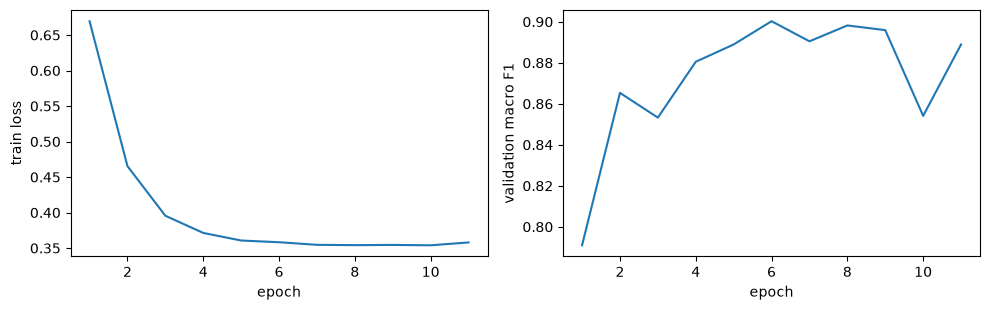

In [6]:
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ep, [h["train_loss"] for h in history]); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss")
ax[1].plot(ep, [h["val_macro_f1"] for h in history]); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation macro F1")
plt.tight_layout(); plt.show()

## 4. Evaluation

Accuracy alone is misleading when classes are imbalanced, because always predicting the largest class already scores well. Every result is therefore shown next to that baseline, together with macro F1 and balanced accuracy.

In [7]:
pred, attn = ca.predict(model, X[te], return_attention=True)
res = ca.evaluate(y[te], pred, y_train=y[tr], target_names=["class 0", "class 1"])
print(ca.summary(res))

accuracy           0.8853
balanced accuracy  0.8527
macro F1           0.8621
weighted F1        0.8837

majority baseline ('0')
  accuracy         0.6907
  macro F1         0.4085

beats baseline on accuracy : True
beats baseline on macro F1 : True


In [8]:
print(res["report"])
print("confusion matrix (rows are true labels)")
print(res["confusion_matrix"])

              precision    recall  f1-score   support

     class 0      0.900     0.938     0.919      1036
     class 1      0.848     0.767     0.805       464

    accuracy                          0.885      1500
   macro avg      0.874     0.853     0.862      1500
weighted avg      0.884     0.885     0.884      1500

confusion matrix (rows are true labels)
[[972  64]
 [108 356]]


**Ceiling on accuracy.** Labels were flipped for 10% of sequences when the data were generated, so no model can exceed about 0.90 here. A result close to that ceiling means the signal was recovered.

## 5. Does attention find the motif?

The window position is known, so this is a check rather than an
interpretation.

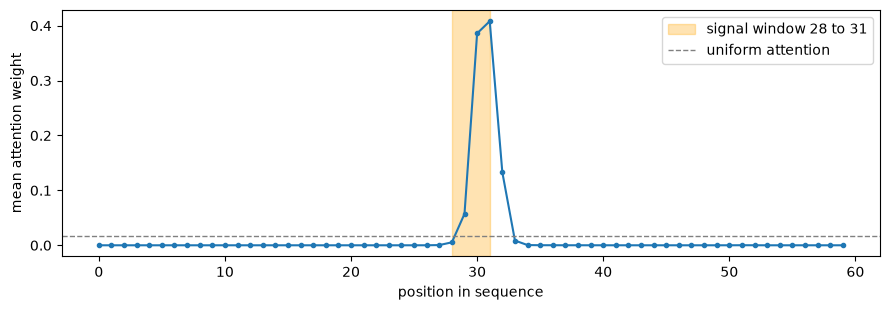

mean attention inside  the signal window : 0.21419
mean attention outside the signal window : 0.00256
enrichment                               : 83.7x
top attended position                    : 31


In [9]:
mean_attn = attn.mean(axis=0)
lo, hi = window

plt.figure(figsize=(9, 3.2))
plt.plot(mean_attn, marker=".")
plt.axvspan(lo, hi - 1, color="orange", alpha=0.3, label=f"signal window {lo} to {hi-1}")
plt.axhline(1 / X.shape[1], ls="--", c="grey", lw=1, label="uniform attention")
plt.xlabel("position in sequence"); plt.ylabel("mean attention weight")
plt.legend(); plt.tight_layout(); plt.show()

inside = mean_attn[lo:hi].mean()
outside = np.delete(mean_attn, np.arange(lo, hi)).mean()
print(f"mean attention inside  the signal window : {inside:.5f}")
print(f"mean attention outside the signal window : {outside:.5f}")
print(f"enrichment                               : {inside / outside:.1f}x")
print(f"top attended position                    : {int(np.argmax(mean_attn))}")

## 6. Padding receives no attention

Padded positions are masked before the softmax. Here half of a batch is padded, and the weight on those positions should be exactly zero.

In [10]:
padded = X[te][:8].copy()
padded[:, 40:] = 0                       # 0 is the padding index
_, w = ca.predict(model, padded, return_attention=True)
print("total attention on padded positions:", float(w[:, 40:].sum()))
print("each row still sums to 1          :", np.allclose(w.sum(axis=1), 1.0))

total attention on padded positions: 0.0
each row still sums to 1          : True


## 7. Summary

On a benchmark with a known answer, the model separated the classes close to the noise ceiling and placed its attention on the window that defines the label. Padding received no weight.

This establishes that the implementation behaves as intended. It says nothing about real repair outcome data, which has its own difficulties: severe class imbalance, deletion placement ambiguity under microhomology, and far fewer independent target sites than sequencing reads.